# DC4 original mock: fit Crab amplitude and NGC 4151 CPL

This focused experiment uses the original three-month full mock. The other 69 sources keep their injected catalog values. A single free Crab anchor scales its nebula, peak 1, bridge, and peak 2 spectra by the same factor; their relative amplitudes and individual light-curve responses remain intact. NGC 4151 has a free CPL with −5 ≤ index ≤ −1. The instrumental background has one free overall rate. Four starts are compared by Poisson log likelihood.


In [ ]:
from pathlib import Path
from copy import deepcopy
import sys
import gc
import hashlib

import astropy.units as u
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display

from astromodels import (
    Cutoff_powerlaw, ExtendedSource, PointSource, Parameter, Powerlaw, Model, load_model,
)
from histpy import Histogram
from threeML import DataList, JointLikelihood, BayesianAnalysis
from threeML.minimizer.minimization import FitFailed, CannotComputeCovariance
from threeML.exceptions.custom_exceptions import BadCovariance
from cosipy.threeml import BinnedSED
from dataclasses import dataclass
from scipy.optimize import brentq, minimize

from cosipy import BinnedData
from cosipy.background_estimation import FreeNormBinnedBackground
from cosipy.data_io import EmCDSBinnedData
from cosipy.event_selection import GoodTimeInterval
from cosipy.interfaces import ThreeMLPluginInterface
from cosipy.response import (
    BinnedInstrumentResponse,
    BinnedThreeMLModelFolding,
    BinnedThreeMLPointSourceResponse,
    BinnedThreeMLExtendedSourceResponse,
    ExtendedSourceResponse,
)
from cosipy.response.FullDetectorResponse import FullDetectorResponse
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.statistics import PoissonLikelihood
from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401


# DC4 recipe interpretation stays in this tutorial; reusable calculations live in cosipy.
import json
import yaml
from astropy.io import fits
from cosipy.response.temporal_profile import LightcurveProfile
from cosipy.response.threeml_temporal_response import (
    ZeroPointSourceResponse, ComponentPointSourceResponse,
    make_weighted_point_source_response,
)
from cosipy.util.megalib import megalib_map_to_galprop_fits

from threeML.plugin_prototype import PluginPrototype
from astromodels import Uniform_prior


## Shared catalog, spatial-template, and histogram helpers


In [ ]:
def load_recipe(path, catalog_path, model):
    # A relocated recipe may be supplied in memory; retain the same validation.
    recipe = deepcopy(path) if isinstance(path, dict) else json.loads(Path(path).read_text())
    if recipe.get('schema') != 'dc4-component-lightcurve-response-v1':
        raise ValueError("Unsupported temporal-response recipe schema")
    if Path(recipe['catalog']).resolve() != Path(catalog_path).resolve():
        raise ValueError("The response recipe belongs to a different catalog")
    if recipe['selection'] not in {'full', 'NGC4151_GTI'} or recipe['time_basis'] != 'elapsed':
        raise ValueError("Expected a full-observation or NGC4151 GTI elapsed-time catalog")
    if set(row['source'] for row in recipe['components']) != set(model.sources):
        raise ValueError("Recipe and catalog source lists differ")
    if any(row['selection'] != recipe['selection'] for row in recipe['components']):
        raise ValueError("Mixed selections in response recipe")
    keys = [(r['source'], r['component']) for r in recipe['components']]
    if len(set(keys)) != len(keys):
        raise ValueError("Duplicate source/component recipe entries")
    return recipe


def component_name(source, label):
    if label in source.components:
        return label
    # v1 recipes store MEGAlib labels rather than astromodels component names.
    crab_names = {'Crab_Nebula': 'nebula', 'Crab_P1': 'peak1',
                  'Crab_Brg': 'bridge', 'Crab_P2': 'peak2'}
    if source.name == 'crab' and crab_names.get(label) in source.components:
        return crab_names[label]
    raise ValueError(f"Unknown temporal component {source.name}/{label}")


def make_temporal_responses(model, recipe, base_history, gti, data,
                            instrument_response, detector_response,
                            exposure_multiplier=1., full_history=None):
    """Build per-source/component responses from the unscaled GTI history.

    Validate temporal factors over the CATALOG selection, which can differ
    from the analysis GTI. Full catalogs require the original full_history:
    response weights remain L(t)/mean_full while exposure is GTI restricted.
    Exposure repetitions multiply response livetimes, not fluxes.
    Responses are computed lazily by cosipy and reused throughout fitting.
    """
    if not np.isfinite(exposure_multiplier) or exposure_multiplier <= 0:
        raise ValueError("Exposure multiplier must be finite and positive")
    starts, stops = np.asarray(gti.tstart_list.unix), np.asarray(gti.tstop_list.unix)
    duration = float(np.sum(stops-starts))
    if duration <= 0 or np.any(stops <= starts):
        raise ValueError("The analysis GTI must have positive duration")
    catalog_selection = recipe.get('selection', 'NGC4151_GTI')
    if catalog_selection == 'full':
        if full_history is None:
            raise ValueError("Full-observation catalogs require the original full_history")
        reference_starts = np.array([full_history.obstime[0].unix])
        reference_stops = np.array([full_history.obstime[-1].unix])
        if np.any(starts < reference_starts[0]-1e-5) or np.any(stops > reference_stops[0]+1e-5):
            raise ValueError("The analysis GTI extends beyond the catalog observation")
    elif catalog_selection == 'NGC4151_GTI':
        reference_starts, reference_stops = starts, stops
    else:
        raise ValueError(f"Unsupported catalog selection: {catalog_selection}")
    reference_duration = float(np.sum(reference_stops-reference_starts))
    if not np.isfinite(reference_duration) or reference_duration <= 0:
        raise ValueError("Invalid catalog reference duration")
    history_starts, history_stops = base_history.intervals_tstart.unix, base_history.intervals_tstop.unix
    rows_by_source = {}
    for row in recipe['components']:
        rows_by_source.setdefault(row['source'], []).append(row)
    overrides, diagnostics = {}, []
    for key, rows in rows_by_source.items():
        source = model.sources[key]
        for row in rows:
            if not np.isclose(row['selected seconds'], reference_duration, rtol=0., atol=1e-4):
                raise ValueError(f"Reference duration differs from the catalog: {key}")
        if not any(row['lightcurve'] for row in rows):
            continue
        if not isinstance(source, PointSource):
            raise NotImplementedError(f"A temporal extended response is required for {key}")
        if any(r['component'] == 'all' for r in rows) and len(rows) != 1:
            raise ValueError(f"Invalid component grouping for {key}")
        component_responses = {}
        for row in rows:
            applied = float(row['applied factor'])
            if not np.isfinite(applied) or applied <= 0:
                raise ValueError(f"Invalid applied factor for {key}")
            if row['lightcurve']:
                profile = LightcurveProfile.from_dat(
                    row['lightcurve'], expected_sha256=row['lightcurve sha256'],
                    repeating=row['repeating'], mode=row['normalization mode'],
                    bins=int(row['simulation bins']),
                )
                mean = float(profile.integral(reference_starts, reference_stops).sum()/reference_duration)
                gti_mean = float(profile.integral(starts, stops).sum()/duration)
                weights = profile.response_weights(history_starts, history_stops, applied)
                del profile
            else:
                mean, gti_mean, weights = 1., 1., np.ones(base_history.nintervals)
            if not np.isclose(mean, row['time factor'], rtol=1e-8, atol=1e-14):
                raise ValueError(f"Temporal factor differs from catalog for {key}/{row['component']}")
            if not np.isclose(applied, max(mean, 1e-30), rtol=1e-8, atol=0.):
                raise ValueError(f"Applied factor differs from catalog for {key}")
            weighted_live = base_history.livetime * weights * exposure_multiplier
            response = make_weighted_point_source_response(
                base_history, weights, data, instrument_response, detector_response,
                exposure_multiplier=exposure_multiplier,
            )
            diagnostics.append({'source': key, 'component': row['component'],
                                'normalization mode': row['normalization mode'],
                                'simulation bins': row['simulation bins'],
                                'catalog selection': catalog_selection,
                                'catalog time factor': mean,
                                'analysis GTI time factor': gti_mean,
                                'response denominator': applied,
                                'weighted response seconds': float(weighted_live.to_value(u.s).sum())})
            if row['component'] == 'all':
                overrides[key] = response
            else:
                name = component_name(source, row['component'])
                if name in component_responses:
                    raise ValueError(f"Duplicate mapped component for {key}/{name}")
                component_responses[name] = response
        if component_responses:
            if set(component_responses) != set(source.components):
                raise ValueError(f"Recipe does not cover all components of {key}")
            overrides[key] = ComponentPointSourceResponse(component_responses)
    return overrides, diagnostics


In [ ]:
SPATIAL_TEMPLATE_NSIDE = 8
SPATIAL_TEMPLATE_FORMAT_TAG = "perMeV_v3"
SPATIAL_DEFINITIONS = {'positrons_26al_line': ('DC3', 'Positrons_from_26Al_line'),
 'positrons_26al_cont': ('DC3', 'Positrons_from_26Al_cont'),
 'positrons_44ti_line': ('DC3', 'Positrons_from_44Ti_line'),
 'positrons_44ti_cont': ('DC3', 'Positrons_from_44Ti_cont'),
 'narrow_bulge_511': ('DC3', 'NB_511'),
 'broad_bulge_511': ('DC3', 'BB_511'),
 'vela_snr_511': ('DC3', 'Vela_SNR_511'),
 'al26_ne2001': ('DC3', '26Al_NE2001'),
 'fe60_ne2001': ('DC3', '60Fe_NE2001'),
 'positrons_thin_disk_cont': ('DC4', 'Positrons_Thin_Disk_cont'),
 'positrons_thin_disk_line': ('DC4', 'Positrons_Thin_Disk_line')}

def resolve_source_asset(source_definition, filename):
    path = source_definition.parent / filename
    candidates = [path, Path(f"{path}.gz")]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Could not resolve {filename!r} next to {source_definition}"
    )


def parse_megalib_blocks(source_definition):
    # Return one property dictionary per DataChallenge.Source block.
    blocks = []
    by_megalib_name = {}
    for raw_line in source_definition.read_text().splitlines():
        line = raw_line.split("#", 1)[0].strip()
        if not line:
            continue
        tokens = line.split()
        if tokens[:1] == ["DataChallenge.Source"]:
            megalib_name = tokens[1]
            block = {"_name": megalib_name}
            blocks.append(block)
            by_megalib_name[megalib_name] = block
            continue
        if "." not in tokens[0]:
            continue
        megalib_name, prop = tokens[0].split(".", 1)
        if megalib_name in by_megalib_name:
            by_megalib_name[megalib_name][prop] = tokens[1:]
    if not blocks:
        raise ValueError(f"No DataChallenge.Source blocks in {source_definition}")
    return blocks


def source_library_path(value, source_library):
    """Relocate a catalog asset without relying on the original user's home."""
    parts = Path(value).parts
    if "Source_Library" not in parts:
        raise ValueError(f"Not a source-library path: {value}")
    relative = Path(*parts[parts.index("Source_Library") + 1:])
    candidate = (Path(source_library) / relative).resolve()
    if not candidate.is_file():
        raise FileNotFoundError(candidate)
    return str(candidate)


def ensure_spatial_template(source_name, output_path, source_library, overwrite=False):
    """Build only missing templates, preserving the generator's conversion."""
    output_path = Path(output_path)
    if output_path.exists() and not overwrite:
        with fits.open(output_path) as hdul:
            if (hdul['SKYMAP'].header.get('NSIDE') != SPATIAL_TEMPLATE_NSIDE
                    or hdul['SKYMAP'].header.get('MAPVERS') != SPATIAL_TEMPLATE_FORMAT_TAG):
                raise ValueError(f"Incompatible cached spatial template: {output_path}")
        return output_path, 'loaded'
    challenge, stem = SPATIAL_DEFINITIONS[source_name]
    matches = sorted((Path(source_library) / challenge / 'sources').rglob(f'{stem}.source'))
    if len(matches) != 1:
        raise ValueError(f"Expected one {stem}.source, found {matches}")
    blocks = parse_megalib_blocks(matches[0])
    if len(blocks) != 1 or len(blocks[0].get('Beam', [])) < 2:
        raise ValueError(f"Expected one coupled map in {matches[0]}")
    map_path = resolve_source_asset(matches[0], blocks[0]['Beam'][1])
    megalib_map_to_galprop_fits(
        map_path, output_path, nside=SPATIAL_TEMPLATE_NSIDE,
        oversample_nside=64, energy_bounds=(100., 10000.), overwrite=overwrite,
    )
    return output_path, 'created'


def prepare_catalog(catalog_path, recipe_input, source_library, template_directory,
                    orientation_path, response_path, binning_path, overwrite=False):
    """Generate templates, relocate external assets, and load without rewriting YAML.

    The YAML and base JSON remain byte-for-byte unchanged. Only
    the in-memory dictionaries receive this computer's paths. Their source
    amplitudes and the recipe's light-curve hashes are never modified.
    """
    from astromodels.core.model_parser import ModelParser
    from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401

    catalog_path = Path(catalog_path)
    contents = yaml.safe_load(catalog_path.read_text())
    recipe = deepcopy(recipe_input)
    if Path(recipe['catalog']).name != catalog_path.name:
        raise ValueError('The recipe refers to a different catalog filename')
    recipe['catalog'] = str(catalog_path.resolve())
    for key, local in [('orientation', orientation_path), ('detector_response', response_path),
                       ('binning', binning_path)]:
        if Path(recipe[key]).name != Path(local).name:
            raise ValueError(f'{key} filename differs from the catalog recipe')
        recipe[key] = str(Path(local).resolve())
    for row in recipe['components']:
        if row['lightcurve']:
            row['lightcurve'] = source_library_path(row['lightcurve'], source_library)

    template_rows = []
    def relocate(node, source_name):
        if isinstance(node, dict):
            for key, value in node.items():
                if key == '_fitsfile' and value:
                    expected_name = f'{source_name}_nside8_perMeV_v3.fits'
                    if Path(value).name != expected_name:
                        raise ValueError(f'Unsupported spatial template: {value}')
                    path, status = ensure_spatial_template(
                        source_name, Path(template_directory) / expected_name,
                        source_library, overwrite=overwrite,
                    )
                    node[key] = str(path.resolve())
                    template_rows.append({'source': source_name, 'status': status, 'file': str(path)})
                elif isinstance(value, str) and 'Source_Library/' in value:
                    node[key] = source_library_path(value, source_library)
                else:
                    relocate(value, source_name)
        elif isinstance(node, list):
            for value in node:
                relocate(value, source_name)
    for source_key, definition in contents.items():
        relocate(definition, source_key.split(' (')[0])
    model = ModelParser(model_dict=contents).get_model()
    recipe = load_recipe(recipe, catalog_path, model)
    return model, recipe, template_rows


In [ ]:
def load_selected_histogram(path, gti, binning_path, already_selected=True):
    """Load explicitly preselected HDF5 or select native FITS events before binning.

    Histogram axes do not encode their GTI. For an already-selected histogram,
    its time-selection provenance is the caller's responsibility. An unselected
    projected histogram is rejected because event times cannot be recovered.
    Native event selection uses half-open [start, stop) GTI intervals.
    """
    import astropy.units as u
    from astropy.coordinates import SkyCoord
    from histpy import Histogram, Axis, Axes, HealpixAxis

    config = yaml.safe_load(Path(binning_path).read_text())
    axes = Axes([
        Axis(config['energy_bins'], unit=u.keV, label='Em'),
        Axis(np.linspace(0., 180., int(180. / config['phi_pix_size']) + 1),
             unit=u.deg, label='Phi'),
        HealpixAxis(nside=config['nside'], scheme=config['scheme'],
                    coordsys='galactic', label='PsiChi'),
    ])
    path = Path(path)
    is_fits = path.name.endswith(('.fits', '.fits.gz'))
    if not is_fits:
        if not already_selected:
            raise ValueError('Use native event FITS to apply a new GTI, not a projected histogram')
        histogram = Histogram.open(path).project('Em', 'Phi', 'PsiChi')
        if histogram.axes != axes:
            raise ValueError(f'Histogram binning differs from agn.yaml: {path}')
        return histogram

    starts = np.asarray(gti.tstart_list.unix, dtype=float)
    stops = np.asarray(gti.tstop_list.unix, dtype=float)
    if (starts.size == 0 or np.any(stops <= starts)
            or np.any(starts[1:] < stops[:-1])):
        raise ValueError('GTI intervals must be positive, sorted and nonoverlapping')
    histogram = Histogram(axes, sparse=True)
    with fits.open(path, memmap=False) as hdul:
        events = hdul[1].data
        for offset in range(0, len(events), 250_000):
            block = events[offset:offset + 250_000]
            times = np.asarray(block['TimeTags'], dtype=float)
            if already_selected:
                selected = np.ones(times.size, dtype=bool)
            else:
                index = np.searchsorted(starts, times, side='right') - 1
                selected = (index >= 0) & (times < stops[np.maximum(index, 0)])
            direction = SkyCoord(
                l=np.asarray(block['Chi galactic'][selected]) * u.deg,
                b=np.asarray(block['Psi galactic'][selected]) * u.deg,
                frame='galactic',
            )
            histogram.fill(np.asarray(block['Energies'][selected]) * u.keV,
                           np.asarray(block['Phi'][selected]) * u.rad, direction)
    return histogram


## Input files and NGC 4151 GTI

The first histogram is the original mock supplied by the user. Figure 1 bins the original DC4 NGC 4151 event FITS under the same pointing GTI and adds the selected instrumental background. Figure 2 uses a source-only HDF5 with altered PL normalization specified as 0.30 times the CPL differential flux at 200 keV. The mock and modified source histograms were preselected to the NGC 4151 field of view; those binned files cannot be cut to another GTI. The original source FITS retains event times and is explicitly selected by this notebook. The first plot uses three-month data for all its fits. Only the second, isolated CPL + PL plot repeats the source and instrumental-background counts and the selected pointing livetime eight times to forecast 24 months.

For provenance: the earlier altered full mock has 21,189 more reconstructed counts than the unedited mock; 17,501 of those additional counts are in the first two `Em` bins (100–251 keV). The two catalog fits therefore use different target signals. This count comparison alone does not establish that either CPL optimizer found the global optimum.


In [ ]:
# Locate the AGN tutorial from its own folder or the cosipy checkout.
notebook_dir = Path.cwd().resolve()
if not (notebook_dir / "agn_paper_plot_style.py").is_file():
    roots = [p for p in (notebook_dir, *notebook_dir.parents) if (p / "cosipy").is_dir()]
    if not roots:
        raise FileNotFoundError("Run from this tutorial folder or the cosipy checkout")
    notebook_dir = roots[0] / "docs/tutorials/spectral_fits/continuum_fit/AGN"
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))

dc4_candidates = [
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files",
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Software_Files/DC4_Files",
]
dc4_files_root = next((p for p in dc4_candidates if p.is_dir()), None)
if dc4_files_root is None:
    raise FileNotFoundError(f"DC4 files not found in {dc4_candidates}")
source_library = Path.home() / "Software/cosi-sim/cosi_sim/Source_Library"
mock_data_path = dc4_files_root / "Mock_Data/Mock_Data_Cut/dc4_mock_dataset_3months_unbinned_data_filtered_with_SAAcut_time_ordered_ngc4151_in_fov_binned.hdf5"
updated_mock_data_path = dc4_files_root / "Mock_Data/Mock_Data_Cut/mock_with_updated_NGC4151_FluxNTH_0p30_time_cut.hdf5"
# The isolated source-only histogram uses a 0.30 PL/CPL ratio at 200 keV.
ngc_original_fits_path = dc4_files_root / (
    "DC4_Sources/DC4/NGC_4151_3months_unbinned_data_filtered_with_SAAcut.fits.gz"
)
ngc_only_source_path = dc4_files_root / (
    "DC4_Sources/DC4_Mod/NGC_4151_ec200_0p30_DC4_COSI_cpl_pl_time_cut_in_fov.hdf5"
)
background_path = dc4_files_root / (
    "Background/Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_"
    "withSAAbck_NGC4151_60deg_fov_cut.hdf5"
)
orientation_path = dc4_files_root / "DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori"
response_path = dc4_files_root / (
    "ResponseContinuum.o3.e100_10000.b10log.s10396905069491."
    "m2284.filtered.nonsparse.binnedimaging.imagingresponse.h5"
)
agn_config = notebook_dir / "agn.yaml"
parallel_catalog_path = notebook_dir / "source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml"
parallel_recipe_path = parallel_catalog_path.with_suffix(".response.json")
spatial_template_directory = dc4_files_root / "DC4_Sources/DC4_Spatial_Templates"
extended_response_path = dc4_files_root / (
    "Extended_Responses/NGC4151_Cut/"
    "DC4_continuum_NGC4151_60deg_GTI_extended_response_nside8.h5"
)
mock_already_gti_selected = True
background_already_gti_selected = True
exposure_multiplier = 1

for path in (source_library, mock_data_path, updated_mock_data_path,
             ngc_original_fits_path,
             ngc_only_source_path, background_path,
             orientation_path, response_path, agn_config, parallel_catalog_path,
             parallel_recipe_path, extended_response_path):
    if not path.exists():
        raise FileNotFoundError(path)
print("Original full mock:", mock_data_path)
print("Updated 0.30 full mock:", updated_mock_data_path)
print("Parallel catalog:", parallel_catalog_path)
print("Original NGC event FITS for Figure 1:", ngc_original_fits_path)
print("Modified NGC source for Figure 2:", ngc_only_source_path)
if exposure_multiplier <= 0:
    raise ValueError("exposure_multiplier must be positive")


In [ ]:
parallel_recipe_input = json.loads(parallel_recipe_path.read_text())
parallel_model, parallel_recipe, template_status = prepare_catalog(
    parallel_catalog_path, parallel_recipe_input, source_library,
    spatial_template_directory, orientation_path, response_path, agn_config,
    overwrite=False,
)
method_models = {"parallel chunks": parallel_model}
method_recipes = {"parallel chunks": parallel_recipe}
if len(parallel_model.sources) != 71 or parallel_model.free_parameters:
    raise RuntimeError("Expected a frozen, 71-entry parallel catalog")
sc_orientation_full = SpacecraftHistory.open(orientation_path)
print("Catalog sources:", len(parallel_model.sources))
display(pd.DataFrame(template_status))


In [ ]:
source_l = parallel_model.ngc4151.position.l.value * u.deg
source_b = parallel_model.ngc4151.position.b.value * u.deg
source_coord = SkyCoord(l=source_l, b=source_b, frame="galactic")

# These settings define the shared NGC 4151 GTI selection.
max_offaxis = 60.0 * u.deg
earth_occ = True

source_gti = GoodTimeInterval.from_pointing_cut(
    source_coord,
    sc_orientation_full,
    max_offaxis,
    earth_occ=earth_occ,
)
sc_orientation_cut = sc_orientation_full.apply_gti(source_gti)

# Repeat the selected pointing history by scaling its interval livetimes.
# The attitude and Earth-occultation selection remain unchanged.
sc_orientation = SpacecraftHistory(
    sc_orientation_cut.obstime,
    sc_orientation_cut.attitude,
    sc_orientation_cut.location,
    livetime=sc_orientation_cut.livetime * exposure_multiplier,
)
sc_orientation.cache_earth_occ = sc_orientation_cut.cache_earth_occ


full_livetime = sc_orientation_full.cumulative_livetime().to_value(u.s)
fov_livetime = sc_orientation_cut.cumulative_livetime().to_value(u.s)
scaled_livetime = sc_orientation.cumulative_livetime().to_value(u.s)
print(f"Full orientation livetime: {full_livetime:,.1f} s")
print(f"Three-month GTI livetime: {fov_livetime:,.1f} s")
print(f"Scaled {(3 * exposure_multiplier)}-month livetime: {scaled_livetime:,.1f} s")


In [ ]:
data_hist = load_selected_histogram(
    mock_data_path, source_gti, agn_config,
    already_selected=mock_already_gti_selected,
)
total_bkg = load_selected_histogram(
    background_path, source_gti, agn_config,
    already_selected=background_already_gti_selected,
)
ngc_original_source_hist = load_selected_histogram(
    ngc_original_fits_path, source_gti, agn_config, already_selected=False,
)
ngc_only_source_hist = load_selected_histogram(
    ngc_only_source_path, source_gti, agn_config, already_selected=True,
)
if not (total_bkg.axes == data_hist.axes == ngc_original_source_hist.axes
        == ngc_only_source_hist.axes):
    raise ValueError("Full mock, NGC-only, and background detector axes differ")
data_hist *= exposure_multiplier
total_bkg *= exposure_multiplier
ngc_original_source_hist *= exposure_multiplier
ngc_only_source_hist *= exposure_multiplier
total_bkg += sys.float_info.min
# Figure 1 uses the original DC4 NGC 4151 events selected by the GTI.
# Figure 2 uses only the altered 0.30 source; both add instrumental background.
# Neither isolated histogram includes the other 70 sky sources or full mock.
comparison_data_hist_three_month = ngc_original_source_hist + total_bkg
one_source_data_hist_three_month = ngc_only_source_hist + total_bkg
print("Original NGC GTI event counts:",
      float(ngc_original_source_hist.to_dense(copy=False).contents.sum()))
print("Figure 1 original source + background counts:",
      float(comparison_data_hist_three_month.to_dense(copy=False).contents.sum()))
print("Figure 2 modified 0.30 source + background counts (three-month base):",
      float(one_source_data_hist_three_month.to_dense(copy=False).contents.sum()))
bkg_dist = {"total_bkg": total_bkg}
background_rate_initial = float(total_bkg.to_dense(copy=False).contents.sum()) / scaled_livetime
if not np.isfinite(background_rate_initial) or background_rate_initial <= 0:
    raise ValueError("Invalid initial instrumental-background rate")
print(f"Initial instrumental-background rate: {background_rate_initial:.6g} Hz")
dr = FullDetectorResponse.open(str(response_path))


In [ ]:
# Construct the ordinary responses once; they do not depend on LC normalization.
unpolarized_components = []
for model in (parallel_model,):
    for source in model.sources.values():
        for component in source.components.values():
            degree = getattr(component.polarization, "degree", None)
            if degree is not None and degree.value != 0.0:
                degree.value = 0.0
                unpolarized_components.append(f"{source.name}.{component.name}")
print("Using unpolarized folding for:", sorted(set(unpolarized_components)))

data = EmCDSBinnedData(data_hist)
instrument_response = BinnedInstrumentResponse(dr, data)
psr = BinnedThreeMLPointSourceResponse(
    data=data, instrument_response=instrument_response, sc_history=sc_orientation,
    energy_axis=dr.axes["Ei"],
    polarization_axis=dr.axes["Pol"] if "Pol" in dr.axes.labels else None,
    nside=2 * data.axes["PsiChi"].nside,
)
if extended_response_path.exists():
    print("Loading cached GTI extended response (about 13 GiB)...")
    extended_response = ExtendedSourceResponse.open(extended_response_path)
else:
    print("Generating the NGC 4151 GTI extended response; this can be slow...")
    extended_response = dr.get_extended_source_response(
        sc_orientation_cut, coordsys="galactic", nside_image=8,
        nside_scatt_map=2 * data.axes["PsiChi"].nside, earth_occ=earth_occ,
    )
    extended_response_path.parent.mkdir(parents=True, exist_ok=True)
    extended_response.write(extended_response_path, overwrite=False)
if extended_response.axes["NuLambda"].nside != 8:
    raise ValueError("Expected an NSIDE-8 extended response")
if extended_response.axes[2:] != data.axes:
    raise ValueError("Extended response and data axes differ")
if extended_response.axes["Ei"] != dr.axes["Ei"]:
    raise ValueError("Point and extended incident-energy axes differ")
extended_response *= exposure_multiplier
esr = BinnedThreeMLExtendedSourceResponse(data=data, precomputed_psr=extended_response)
print("Shared ordinary responses are ready.")


## Injected references and fit helpers

The original DC4 source library supplies the NGC 4151 injected spectrum. For the catalog plot, read its tabulated `.dat` spectrum directly instead of using the altered 0.30 reference. The isolated plot uses the 0.30 CPL + PL model. The catalog fit itself replaces NGC 4151 with a free CPL; the other 70 sources remain fixed.


In [ ]:
def make_fit_model(model):
    """Replace only NGC 4151's fixed injection spectrum with a free CPL."""
    assert not model.free_parameters
    source = model.ngc4151
    shape = source.spectrum.main.composite
    cpl = Cutoff_powerlaw(
        K=shape.K_1.value, piv=shape.piv_1.value,
        index=shape.index_1.value, xc=shape.xc_1.value,
    )
    fitted_source = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=cpl,
    )
    for parameter in fitted_source.parameters.values():
        parameter.fix = True
    model.remove_source("ngc4151")
    model.add_source(fitted_source)
    shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
    shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
    shape.K.delta, shape.K.fix = 0.1 * shape.K.value, False
    # astromodels uses a signed exponent: photon index Γ>0 means index<0.
    # Keep the injected index -1.75 inside the allowed scan.
    shape.index.min_value, shape.index.max_value = -5., -1.0
    shape.index.delta, shape.index.fix = 0.1, False
    shape.xc.min_value, shape.xc.max_value = 100., 10000.
    shape.xc.delta, shape.xc.fix = 0.1 * shape.xc.value, False
    shape.piv.fix = True
    expected = {
        "ngc4151.spectrum.main.Cutoff_powerlaw.K",
        "ngc4151.spectrum.main.Cutoff_powerlaw.index",
        "ngc4151.spectrum.main.Cutoff_powerlaw.xc",
    }
    if set(model.free_parameters) != expected:
        raise ValueError("Catalog CPL fit must free only NGC 4151 K, index and xc")
    return model


In [ ]:
def fit_joint_with_fallback(joint, label):
    """Fit the model and explicitly reject missing or invalid covariance."""
    initial_values = {name: par.value for name, par in joint._free_parameters.items()}
    try:
        joint.fit(quiet=True)
    except (FitFailed, CannotComputeCovariance, BadCovariance) as exc:
        print(f"{label}: MINUIT {type(exc).__name__}; retrying with SCIPY")
        # A failed MIGRAD may leave astromodels at its last trial point.
        # A covariance failure happens after a valid minimum, so retain it.
        if isinstance(exc, FitFailed):
            for name, par in joint._free_parameters.items():
                par.value = initial_values[name]
        joint.set_minimizer("SCIPY")
        try:
            joint.fit(quiet=True)
        except (CannotComputeCovariance, BadCovariance):
            joint.fit(quiet=True, compute_covariance=False)
    joint.restore_best_fit()
    covariance = np.atleast_2d(np.asarray(joint.results.covariance_matrix, dtype=float))
    covariance_valid = (
        np.all(np.isfinite(covariance))
        and np.all(np.diag(covariance) > 0)
    )
    if covariance_valid:
        try:
            np.linalg.cholesky(covariance)
        except np.linalg.LinAlgError:
            covariance_valid = False
    if not covariance_valid:
        print(f"{label}: no valid covariance; global 68% band is unavailable. "
              "A threeML '+/- 0' after compute_covariance=False is only a placeholder.")
    return covariance_valid


def parameter_intervals_68(results, parameters, covariance_valid):
    """Return valid covariance-based 68% intervals for fitted parameters.

    threeML's equal-tail intervals use random draws from the covariance and
    reject samples outside parameter bounds. When that truncation shifts the
    equal-tail interval away from the MLE, use the local 1-sigma covariance
    interval in the parameter's internal (possibly log) coordinates instead.
    """
    if not covariance_valid:
        return None
    covariance = np.atleast_2d(np.asarray(results.covariance_matrix, dtype=float))
    free = results.optimized_model.free_parameters
    names = list(free)
    intervals = {}
    for label, parameter in parameters.items():
        if parameter.path not in free:
            continue
        fitted_parameter = free[parameter.path]
        value = float(fitted_parameter.value)
        # A Hessian interval at a hard boundary can look spuriously tiny.
        # Report no two-sided 68% interval for a pegged parameter; use a
        # profile likelihood or a separately stated fixed-index fit instead.
        lower_bound = fitted_parameter.min_value
        upper_bound = fitted_parameter.max_value
        if lower_bound is not None and upper_bound is not None:
            bound_tolerance = 1e-5 * (float(upper_bound) - float(lower_bound))
        else:
            bound_tolerance = 1e-8 * max(abs(value), 1e-12)
        if ((lower_bound is not None and value - float(lower_bound) <= bound_tolerance)
                or (upper_bound is not None and float(upper_bound) - value <= bound_tolerance)):
            print(f"{label}: parameter is at a bound; two-sided 68% interval unavailable")
            continue
        try:
            lower, upper = map(float,
                               results.get_variates(parameter.path).equal_tail_interval(cl=0.68))
            if not (np.isfinite(lower) and np.isfinite(upper)
                    and lower <= value <= upper and lower < upper):
                raise ValueError("Bound-truncated samples do not enclose the MLE")
        except (AssertionError, BadCovariance, CannotComputeCovariance, ValueError):
            i = names.index(parameter.path)
            sigma_internal = float(np.sqrt(covariance[i, i]))
            center_internal = float(fitted_parameter._get_internal_value())
            if fitted_parameter.has_transformation():
                transform = fitted_parameter.transformation
                lower = float(transform.backward(center_internal - sigma_internal))
                upper = float(transform.backward(center_internal + sigma_internal))
            else:
                lower = center_internal - sigma_internal
                upper = center_internal + sigma_internal
            if fitted_parameter.min_value is not None:
                lower = max(lower, float(fitted_parameter.min_value))
            if fitted_parameter.max_value is not None:
                upper = min(upper, float(fitted_parameter.max_value))
            print(f"{label}: using local-covariance 68% interval because "
                  "threeML's bound-truncated equal-tail interval excludes the best fit")
        if (np.isfinite(lower) and np.isfinite(upper)
                and lower <= value <= upper and lower < upper):
            intervals[label] = [lower, upper]
        else:
            print(f"{label}: 68% interval unavailable after covariance check")
    return intervals or None


def format_parameter_68(record, label, spec):
    """Format a fitted value with asymmetric 68% errors, if they were saved."""
    value = float(record[label])
    interval = (record.get("parameter intervals 68") or {}).get(label)
    if interval is None:
        return f"{value:{spec}} (68% unavailable)"
    lower, upper = map(float, interval)
    if not (np.isfinite(lower) and np.isfinite(upper)
            and lower <= value <= upper and lower < upper):
        return f"{value:{spec}} (68% unavailable)"
    return (f"{value:{spec}} "
            f"(−{value - lower:{spec}}/+{upper - value:{spec}})")


def refresh_dc4_response_integrators():
    """Use on-disk spectral and diffuse integration code in a live kernel."""
    import importlib
    import cosipy.response.integrals as response_integrals
    import cosipy.response.functions_3d as functions_3d

    importlib.reload(response_integrals)
    importlib.reload(functions_3d)
    extended_module = importlib.import_module("cosipy.response.ExtendedSourceResponse")
    extended_module.get_integrated_extended_model_3d = (
        functions_3d.get_integrated_extended_model_3d
    )


def local_log_flux_band(results, energies_keV, spectral_flux):
    """Local 68% covariance band centered on the maximum-likelihood spectrum.

    threeML's equal-tail propagated samples are truncated by hard parameter
    bounds; their pointwise quantiles can exclude the best-fit curve. The
    covariance is in astromodels' internal parameter coordinates. Apply the
    delta method to log flux so both band edges stay positive and enclose the
    maximum-likelihood curve. This is a local Gaussian approximation.
    """
    parameters = list(results.optimized_model.free_parameters.values())
    covariance = np.atleast_2d(np.asarray(results.covariance_matrix, dtype=float))
    if covariance.shape != (len(parameters), len(parameters)):
        raise ValueError("Covariance and free-parameter dimensions differ")
    if not np.all(np.isfinite(covariance)):
        raise ValueError("Cannot make a band from a nonfinite covariance")
    centers = np.array([p._get_internal_value() for p in parameters], dtype=float)
    energies = np.asarray(energies_keV, dtype=float)

    def physical_values(internal):
        return {p.path: (float(p.transformation.backward(x))
                         if p.has_transformation() else float(x))
                for p, x in zip(parameters, internal)}

    best = np.asarray(spectral_flux(physical_values(centers), energies), dtype=float)
    if np.any(best <= 0) or not np.all(np.isfinite(best)):
        raise ValueError("Best-fit spectral flux is invalid")
    jacobian = np.zeros((len(energies), len(parameters)))
    for j, center in enumerate(centers):
        step = 1e-4 * max(1.0, abs(center))
        plus, minus = centers.copy(), centers.copy()
        plus[j] += step
        minus[j] -= step
        f_plus = np.asarray(spectral_flux(physical_values(plus), energies), dtype=float)
        f_minus = np.asarray(spectral_flux(physical_values(minus), energies), dtype=float)
        if np.any(f_plus <= 0) or np.any(f_minus <= 0):
            raise ValueError("Cannot differentiate the log spectral flux")
        jacobian[:, j] = (np.log(f_plus) - np.log(f_minus)) / (2.0 * step)
    variance = np.einsum('ij,jk,ik->i', jacobian, covariance, jacobian)
    if np.any(variance < -1e-9):
        raise ValueError("Negative propagated log-flux variance")
    sigma = np.sqrt(np.maximum(variance, 0.0))
    low, high = best * np.exp(-sigma), best * np.exp(sigma)
    assert np.all(low <= best) and np.all(best <= high)
    return low, high


## One Crab scale with fixed component ratios


In [ ]:
from astromodels import Line
import logging

class _QuietLinkedParameterWarning(logging.Filter):
    """Hide astromodels warnings from its internal linked-K bookkeeping."""
    def filter(self, record):
        message = record.getMessage()
        return not ("either linked or has auxiliary variables" in message
                    or "above the new maximum" in message
                    or "below the new minimum" in message)

logging.getLogger("astromodels.core.parameter").addFilter(
    _QuietLinkedParameterWarning()
)

def add_one_crab_scale(model):
    """Use nebula K as the anchor and tie the other three K values to it."""
    crab = model.crab
    original = {name: float(component.shape.K.value)
                for name, component in crab.components.items()}
    if set(original) != {"nebula", "peak1", "bridge", "peak2"}:
        raise RuntimeError("Unexpected Crab component list")
    anchor = crab.components["nebula"].shape.K
    anchor_k = original["nebula"]
    anchor.min_value, anchor.max_value = 0.5*anchor_k, 1.5*anchor_k
    anchor.delta, anchor.fix = 0.05*anchor_k, False
    for name, component in crab.components.items():
        if name == "nebula":
            continue
        ratio = original[name] / anchor_k
        link = Line(a=0.0, b=ratio)
        link.a.fix = True
        link.b.fix = True
        model.link(component.shape.K, anchor, link)
    ngc_shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
    expected = {anchor.path, ngc_shape.K.path,
                ngc_shape.index.path, ngc_shape.xc.path}
    if set(model.free_parameters) != expected:
        raise RuntimeError(f"Unexpected free sky parameters: {list(model.free_parameters)}")
    return anchor, anchor_k, original

# Build the temporal templates once. They depend on pointing and light curves,
# rather than on the CPL or Crab normalization starting values.
refresh_dc4_response_integrators()
energy = np.geomspace(100., 10000., 400)
response_model = make_fit_model(deepcopy(parallel_model))
response_crab_anchor, _, crab_original_k = add_one_crab_scale(response_model)
point_responses, temporal_diagnostics = make_temporal_responses(
    response_model, parallel_recipe, sc_orientation_cut, source_gti, data,
    instrument_response, dr, exposure_multiplier=exposure_multiplier,
    full_history=sc_orientation_full,
)
print(f"Reusable response mappings: {len(point_responses)}")
print("Original Crab component K values:", crab_original_k)


## Four independent starts for the joint fit

The first full-catalog fold is expensive. Each trial writes its summary to a small JSON file immediately, so completed starts remain reviewable if a later trial fails. The maximum Poisson log likelihood selects the result; a missing covariance is reported rather than interpreted as a zero uncertainty.


In [ ]:
FIT_STARTS = [
    {"label": "catalog", "K": 1.4102261599073976e-5, "index": -1.75,
     "xc (keV)": 200.0, "Crab scale": 1.00},
    {"label": "isolated_original", "K": 9.096716573604494e-6, "index": -2.02,
     "xc (keV)": 330.0, "Crab scale": 0.94},
    {"label": "hard_cutoff", "K": 1.10e-5, "index": -1.05,
     "xc (keV)": 140.0, "Crab scale": 0.94},
    {"label": "soft_cutoff", "K": 1.50e-5, "index": -2.50,
     "xc (keV)": 500.0, "Crab scale": 1.08},
]
fit_records = []
best_record = None
best_objects = None
fit_summary_path = notebook_dir / "plots/NGC4151_DC4_original_mock_Crab_NGC_multistart.json"

def run_start(start):
    model = make_fit_model(deepcopy(parallel_model))
    crab_anchor, anchor_k, original = add_one_crab_scale(model)
    ngc = model.ngc4151.spectrum.main.Cutoff_powerlaw
    ngc.K.value = start["K"]
    ngc.index.value = start["index"]
    ngc.xc.value = start["xc (keV)"]
    crab_anchor.value = anchor_k * start["Crab scale"]
    background = FreeNormBinnedBackground(
        {"total_bkg": total_bkg}, sc_history=sc_orientation, copy=True,
    )
    folding = BinnedThreeMLModelFolding(
        data=data, point_source_response=psr, extended_source_response=esr,
        source_specific_point_source_responses=point_responses,
    )
    likelihood = PoissonLikelihood(data, folding, background)
    plugin = ThreeMLPluginInterface("cosi", likelihood, folding, background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", background_rate_initial, min_value=0., max_value=50.,
        delta=max(0.05*background_rate_initial, 1e-6), unit=u.Hz,
    )
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    initial_loglike = float(plugin.get_log_like())
    covariance_valid = fit_joint_with_fallback(joint, start["label"])
    loglike = float(plugin.get_log_like())
    if not np.isfinite(loglike) or loglike < initial_loglike - 1e-3:
        raise RuntimeError(f"{start['label']}: fit worsened the Poisson likelihood")
    results = joint.results
    fitted_model = results.optimized_model
    ngc_fit = fitted_model.ngc4151.spectrum.main.Cutoff_powerlaw
    crab_k = fitted_model.crab.components["nebula"].shape.K
    crab_scale = float(crab_k.value / anchor_k)
    component_ratios = {name: float(fitted_model.crab.components[name].shape.K.value
                                    / original[name])
                        for name in original}
    if not np.allclose(list(component_ratios.values()), crab_scale, rtol=1e-9):
        raise RuntimeError("Crab component ratios changed during the fit")
    intervals = parameter_intervals_68(
        results, {"K": ngc_fit.K, "index": ngc_fit.index,
                  "xc (keV)": ngc_fit.xc, "Crab anchor K": crab_k,
                  "background (Hz)": plugin.bkg_parameter["total_bkg"]},
        covariance_valid,
    )
    record = {
        "start": start["label"], "initial values": start,
        "initial log likelihood": initial_loglike,
        "log likelihood": loglike, "covariance valid": bool(covariance_valid),
        "K": float(ngc_fit.K.value), "index": float(ngc_fit.index.value),
        "xc (keV)": float(ngc_fit.xc.value),
        "Crab scale": crab_scale, "Crab component ratios": component_ratios,
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "parameter intervals 68": intervals,
    }
    low = high = None
    index_at_bound = abs(float(ngc_fit.index.value) - float(ngc_fit.index.max_value)) < 1e-2
    if index_at_bound:
        print(f"{start['label']}: index is at its upper bound; no reliable two-sided 68% band")
    if covariance_valid and not index_at_bound:
        try:
            pivot = float(ngc_fit.piv.value)
            def flux(values, e):
                return values[ngc_fit.K.path] * (e/pivot)**values[ngc_fit.index.path] * np.exp(
                    -e/values[ngc_fit.xc.path])
            low, high = local_log_flux_band(results, energy, flux)
        except ValueError as exc:
            print(f"{start['label']}: local 68% band unavailable ({exc})")
    return record, {"joint": joint, "model": model, "folding": folding,
                    "background": background, "low": low, "high": high}

for start in FIT_STARTS:
    print(f"Running {start['label']}...", flush=True)
    try:
        record, objects = run_start(start)
    except (FitFailed, CannotComputeCovariance, BadCovariance, ValueError,
            RuntimeError) as exc:
        record = {"start": start["label"], "initial values": start,
                  "status": type(exc).__name__, "message": str(exc)}
        print(f"  failed: {type(exc).__name__}: {exc}", flush=True)
    else:
        record["status"] = "converged"
        if best_record is None or record["log likelihood"] > best_record["log likelihood"]:
            best_record, best_objects = record, objects
        print(f"  log L={record['log likelihood']:.6f}, Crab scale={record['Crab scale']:.4f}, "
              f"NGC index={record['index']:.3f}", flush=True)
    fit_records.append(record)
    fit_summary_path.parent.mkdir(parents=True, exist_ok=True)
    fit_summary_path.write_text(json.dumps({
        "catalog": str(parallel_catalog_path.resolve()),
        "catalog sha256": hashlib.sha256(parallel_catalog_path.read_bytes()).hexdigest(),
        "mock": str(mock_data_path.resolve()),
        "Crab scale bounds": [0.5, 1.5], "NGC index bounds": [-5.0, -1.0],
        "starts": fit_records,
    }, indent=2) + "\n")
    gc.collect()

converged = [row for row in fit_records if row.get("status") == "converged"]
if not converged:
    raise RuntimeError("All four Crab + NGC fits failed")
assert best_record is not None and best_objects is not None
print("Selected start:", best_record["start"])
for key in ("K", "index", "xc (keV)", "Crab scale", "background (Hz)"):
    print(f"  {key}: {best_record[key]:.6g}")
print("  log likelihood:",best_record["log likelihood"])
if np.isclose(best_record["index"], -1.0, atol=0.01):
    print("NGC CPL index is near its physical upper bound; inspect residuals.")
display(pd.DataFrame(converged)[["start", "log likelihood", "K", "index",
                                 "xc (keV)", "Crab scale", "background (Hz)",
                                 "covariance valid"]].sort_values("log likelihood", ascending=False))


## Best-fit spectrum and observed versus model counts


In [ ]:
from agn_paper_plot_style import BLUE, ink, paper_style, style_axis

# Compare with the original DC4 tabulated NGC 4151 injection.
original_ngc_spectrum_path = (source_library / 'DC4/sources/Extragalactic/NGC_4151/'
                              'NGC4151_ec200_TH_and_NTH_COSI.dat')
with original_ngc_spectrum_path.open() as spectrum_file:
    original_spectrum = np.asarray([
        [float(fields[1]), float(fields[2])] for line in spectrum_file
        if (fields := line.split()) and fields[0] == 'DP'
    ], dtype=float)
original_energy_keV, original_photon_flux = original_spectrum.T

def original_injected_flux(energies_keV):
    # The MEGAlib file uses linear interpolation in energy and flux.
    return np.interp(energies_keV, original_energy_keV, original_photon_flux,
                     left=np.nan, right=np.nan)

def injected_thermal_flux(energies_keV):
    e = np.asarray(energies_keV, dtype=float)
    k200 = 0.15 * 200.0**(-1.75)
    return k200 * (e / 200.0)**(-1.75) * np.exp(-e / 200.0)

def _dense_counts(histogram):
    values = histogram.to_dense(copy=False).contents
    if hasattr(values, "compute"):
        values = values.compute()
    if hasattr(values, "value"):
        values = values.value
    return np.asarray(values, dtype=float).copy()

# Inspect the fitted NGC spectrum and the measured-energy residual, without
# interpreting a high likelihood as proof that every source shape is correct.
best_model = best_objects["joint"].results.optimized_model
best_ngc = best_model.ngc4151.spectrum.main.Cutoff_powerlaw
plot_e = np.geomspace(100., 10000., 400)
fit_flux = np.asarray([best_ngc.evaluate_at(e) for e in plot_e], dtype=float)
thermal_flux = injected_thermal_flux(plot_e)
injected_total = original_injected_flux(plot_e)
keV_to_erg = u.keV.to(u.erg)
with paper_style("light", 22):
    fig, (ax, rx) = plt.subplots(2, 1, figsize=(11, 11), constrained_layout=True)
    style_axis(ax, "light", 22)
    style_axis(rx, "light", 22)
    ax.plot(plot_e/1000., keV_to_erg*plot_e**2*injected_total,
            color=ink("light"), ls=":", label="Original injected total")
    ax.plot(plot_e/1000., keV_to_erg*plot_e**2*thermal_flux,
            color="0.5", ls="--", label="Injected thermal CPL")
    ax.plot(plot_e/1000., keV_to_erg*plot_e**2*fit_flux,
            color=BLUE, label="Crab + NGC fit")
    if best_objects["low"] is not None:
        ax.fill_between(energy/1000., keV_to_erg*energy**2*best_objects["low"],
                        keV_to_erg*energy**2*best_objects["high"],
                        color=BLUE, alpha=0.25)
    ax.set(xscale="log", yscale="log", xlim=(0.1, 10.),
           xlabel="Energy (MeV)",
           ylabel=r"Energy flux (erg cm$^{-2}$ s$^{-1}$)")
    ax.legend(frameon=False)
    predicted = best_objects["folding"].expectation(copy=True)
    predicted += best_objects["background"].expectation(copy=True)
    data_em = _dense_counts(data_hist.project("Em"))
    model_em = _dense_counts(predicted.project("Em"))
    edges = data_hist.axes["Em"].edges.to_value(u.keV)
    centers = np.sqrt(edges[:-1]*edges[1:])/1000.
    rx.axhline(0., color=ink("light"), lw=1.5)
    rx.plot(centers, (data_em-model_em)/np.maximum(data_em,1.),
            "o-", color=BLUE)
    rx.set(xscale="log", xlim=(0.1, 10.), xlabel="Measured energy (MeV)",
           ylabel="(Observed − model) / observed")
    plt.show()
print("Observed counts:",float(data_em.sum()))
print("Model counts:",float(model_em.sum()))


## Why the CPL index reaches its upper bound

The four-start fit above reaches index = −1 even when one common Crab normalization is free. The saved checks below compare it with (1) a fit that fixes the index at the injected −1.75 and (2) a fit with separate Crab, MAXI J1820, and 4C+21.35 flare normalization scales. They use the same original mock, GTI, catalog, source responses, and background. The first comparison has a ΔTS of 3.92 for freeing the index; the second improves the overall likelihood but still leaves the index at −1. Neither check justifies reporting a narrow two-sided index error at the boundary. The Figure 1 plot omits that covariance band until a valid interval is available. These checks do not change the paper fit or calibrate the catalog from the simulated source FITS files.


In [ ]:
# Review the saved diagnostic fits without rebuilding the 13-GiB extended response.
# To regenerate them in this kernel, run the two optional functions in the next cell.
base = json.loads((notebook_dir / "plots/NGC4151_DC4_original_mock_Crab_NGC_multistart.json").read_text())
fixed = json.loads((notebook_dir / "plots/NGC4151_DC4_original_mock_Crab_NGC_fixed_index_comparison.json").read_text())
nuisance = json.loads((notebook_dir / "plots/NGC4151_DC4_original_mock_three_nuisance_scales.json").read_text())
best_free = max((r for r in base["starts"] if r.get("status") == "converged"),
                key=lambda r: r["log likelihood"])
assert fixed["data"] == nuisance["data"] == base["mock"]
assert fixed["catalog"] == nuisance["catalog"] == base["catalog"]
comparison = pd.DataFrame([
    {"fit": "NGC index free; one Crab scale", "index": best_free["index"],
     "cutoff (keV)": best_free["xc (keV)"], "log likelihood": best_free["log likelihood"],
     "ΔTS vs first": 0.},
    {"fit": "NGC index fixed at −1.75; one Crab scale", "index": fixed["fixed NGC index"],
     "cutoff (keV)": fixed["xc keV"], "log likelihood": fixed["fixed-index log likelihood"],
     "ΔTS vs first": -fixed["delta TS index free vs fixed"]},
    {"fit": "NGC index free; three nuisance scales", "index": nuisance["NGC index"],
     "cutoff (keV)": nuisance["NGC xc keV"], "log likelihood": nuisance["three-nuisance log likelihood"],
     "ΔTS vs first": nuisance["delta TS three nuisances vs Crab alone"]},
])
display(comparison)
print("Three-source normalization scales:",
      {key: nuisance[key] for key in ("Crab scale", "MAXI J1820 scale", "4C+21.35 flare scale")})
if abs(best_free["index"] - base["NGC index bounds"][1]) < 1e-2:
    print("The free index is pegged: a covariance-based two-sided 68% index interval is invalid.")


In [ ]:
# Optional regeneration. Run cells 1–16 first so the shared responses are in memory.
# The two functions are intentionally separate; either can take several minutes.
def rerun_fixed_injected_index():
    saved = json.loads((notebook_dir / "plots/NGC4151_DC4_original_mock_Crab_NGC_multistart.json").read_text())
    best = max((r for r in saved["starts"] if r.get("status") == "converged"),
               key=lambda r: r["log likelihood"])
    fit_model = make_fit_model(deepcopy(parallel_model))
    crab_anchor, crab_anchor_k, _ = add_one_crab_scale(fit_model)
    ngc = fit_model.ngc4151.spectrum.main.Cutoff_powerlaw
    ngc.K.value, ngc.index.value, ngc.xc.value = 1.4102261599073976e-5, -1.75, 200.
    ngc.index.fix = True
    crab_anchor.value = crab_anchor_k * best["Crab scale"]
    fit_background = FreeNormBinnedBackground(
        {"total_bkg": total_bkg}, sc_history=sc_orientation, copy=True)
    folding = BinnedThreeMLModelFolding(
        data=data, point_source_response=psr, extended_source_response=esr,
        source_specific_point_source_responses=point_responses)
    plugin = ThreeMLPluginInterface(
        "cosi_index_fixed", PoissonLikelihood(data, folding, fit_background),
        folding, fit_background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", best["background (Hz)"], min_value=0., max_value=50.,
        delta=max(0.05 * background_rate_initial, 1e-6), unit=u.Hz)
    joint = JointLikelihood(fit_model, DataList(plugin), verbose=False)
    covariance_valid = fit_joint_with_fallback(joint, "NGC fixed index −1.75")
    result_model = joint.results.optimized_model
    result_ngc = result_model.ngc4151.spectrum.main.Cutoff_powerlaw
    loglike = float(plugin.get_log_like())
    result = {
        "data": str(mock_data_path), "catalog": str(parallel_catalog_path),
        "fixed NGC index": -1.75, "fixed-index log likelihood": loglike,
        "free-index log likelihood": best["log likelihood"],
        "delta TS index free vs fixed": 2 * (best["log likelihood"] - loglike),
        "K": float(result_ngc.K.value), "xc keV": float(result_ngc.xc.value),
        "Crab scale": float(result_model.crab.components["nebula"].shape.K.value / crab_anchor_k),
        "background Hz": float(plugin.bkg_parameter["total_bkg"].value),
        "covariance valid": bool(covariance_valid),
    }
    path = notebook_dir / "plots/NGC4151_DC4_original_mock_Crab_NGC_fixed_index_comparison.json"
    path.write_text(json.dumps(result, indent=2) + "\n")
    print("Saved", path)
    return result


def rerun_three_nuisance_scales(*, index_upper=-1.0, index_start=-1.1, K_start=None,
                                  xc_start=None, crab_start=None, maxi_start=0.82,
                                  flare_start=0.94, background_start=None, output_path=None):
    saved = json.loads((notebook_dir / "plots/NGC4151_DC4_original_mock_Crab_NGC_multistart.json").read_text())
    best = max((r for r in saved["starts"] if r.get("status") == "converged"),
               key=lambda r: r["log likelihood"])
    fit_model = make_fit_model(deepcopy(parallel_model))
    crab_anchor, crab_anchor_k, _ = add_one_crab_scale(fit_model)
    ngc = fit_model.ngc4151.spectrum.main.Cutoff_powerlaw
    ngc.index.max_value = index_upper
    ngc.K.value = best["K"] if K_start is None else K_start
    ngc.index.value = index_start
    ngc.xc.value = best["xc (keV)"] if xc_start is None else xc_start
    crab_anchor.value = crab_anchor_k * (best["Crab scale"] if crab_start is None else crab_start)
    # Keep MAXI J1820's two spectral components in their injected ratio.
    maxi = fit_model.maxi_j1820.spectrum.main.composite
    maxi_anchor, maxi_k, maxi_other_k = maxi.K_1, float(maxi.K_1.value), float(maxi.K_2.value)
    maxi_anchor.min_value, maxi_anchor.max_value = 0.6 * maxi_k, 1.3 * maxi_k
    maxi_anchor.delta, maxi_anchor.fix = 0.05 * maxi_k, False
    link = Line(a=0., b=maxi_other_k / maxi_k)
    link.a.fix = link.b.fix = True
    fit_model.link(maxi.K_2, maxi_anchor, link)
    maxi_anchor.value = maxi_start * maxi_k
    flare = fit_model.four_c_21p35_flare.spectrum.main.SpecFromDat.K
    flare_k = float(flare.value)
    flare.min_value, flare.max_value = 0.7 * flare_k, 1.3 * flare_k
    flare.delta, flare.fix = 0.05 * flare_k, False
    flare.value = flare_start * flare_k
    fit_background = FreeNormBinnedBackground(
        {"total_bkg": total_bkg}, sc_history=sc_orientation, copy=True)
    folding = BinnedThreeMLModelFolding(
        data=data, point_source_response=psr, extended_source_response=esr,
        source_specific_point_source_responses=point_responses)
    plugin = ThreeMLPluginInterface(
        "cosi_three_nuisances", PoissonLikelihood(data, folding, fit_background),
        folding, fit_background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", best["background (Hz)"] if background_start is None else background_start,
        min_value=0., max_value=50.,
        delta=max(0.05 * background_rate_initial, 1e-6), unit=u.Hz)
    joint = JointLikelihood(fit_model, DataList(plugin), verbose=False)
    try:
        joint.fit(quiet=True, compute_covariance=False)  # screening fit only
    except FitFailed:
        joint.set_minimizer("SCIPY")
        joint.fit(quiet=True, compute_covariance=False)
    joint.restore_best_fit()
    fitted = joint.results.optimized_model
    result_ngc = fitted.ngc4151.spectrum.main.Cutoff_powerlaw
    loglike = float(plugin.get_log_like())
    result = {
        "data": str(mock_data_path), "catalog": str(parallel_catalog_path),
        "index bounds": [-5.0, index_upper],
        "three-nuisance log likelihood": loglike,
        "single-Crab log likelihood": best["log likelihood"],
        "delta TS three nuisances vs Crab alone": 2 * (loglike - best["log likelihood"]),
        "NGC K": float(result_ngc.K.value), "NGC index": float(result_ngc.index.value),
        "NGC xc keV": float(result_ngc.xc.value),
        "Crab scale": float(fitted.crab.components["nebula"].shape.K.value / crab_anchor_k),
        "MAXI J1820 scale": float(fitted.maxi_j1820.spectrum.main.composite.K_1.value / maxi_k),
        "4C+21.35 flare scale": float(fitted.four_c_21p35_flare.spectrum.main.SpecFromDat.K.value / flare_k),
        "background Hz": float(plugin.bkg_parameter["total_bkg"].value),
        "covariance computed": False,
    }
    path = (Path(output_path) if output_path is not None else
            notebook_dir / "plots/NGC4151_DC4_original_mock_three_nuisance_scales.json")
    path.write_text(json.dumps(result, indent=2) + "\n")
    print("Saved", path)
    return result


## Wider negative-index range, with three free nuisance normalizations

This diagnostic widens only the NGC 4151 CPL index to −5…−0.01. Crab, MAXI J1820, and the 4C+21.35 flare each retain one free overall normalization; the MAXI spectral-component ratio and all Crab component ratios remain fixed. The default paper fit is unchanged. The saved results below can be reviewed without running the expensive fits. To regenerate them, run cells 1–16 to prepare the responses, then call `rerun_wide_index_multistart()` from the next cell.
All three starts moved to the new upper boundary. The best screening fit has index −0.01005, cutoff 128.4 keV, and ΔTS = 2.47 relative to the same three-source fit with the old −1 upper bound. This is a boundary diagnosis, not a measured hard spectral index; covariance was not computed.


In [ ]:
def rerun_wide_index_multistart():
    """Refit the original mock from three starts with −5 <= index <= −0.01.

    Run notebook cells 1–16 first. Each completed start is saved immediately,
    so an interruption does not discard earlier results. No covariance is
    claimed for these screening fits.
    """
    old = json.loads((notebook_dir / "plots/NGC4151_DC4_original_mock_three_nuisance_scales.json").read_text())
    configurations = [
        dict(label="previous_three_source", K_start=old["NGC K"], index_start=-0.95,
             xc_start=old["NGC xc keV"], crab_start=old["Crab scale"],
             maxi_start=old["MAXI J1820 scale"], flare_start=old["4C+21.35 flare scale"],
             background_start=old["background Hz"]),
        dict(label="injected_index", K_start=1.4102261599073976e-5, index_start=-1.75,
             xc_start=200., crab_start=0.95, maxi_start=0.8, flare_start=0.95,
             background_start=background_rate_initial),
        dict(label="very_hard", K_start=7.0e-6, index_start=-0.1,
             xc_start=240., crab_start=old["Crab scale"],
             maxi_start=old["MAXI J1820 scale"], flare_start=old["4C+21.35 flare scale"],
             background_start=old["background Hz"]),
    ]
    summary_path = notebook_dir / "plots/NGC4151_DC4_original_mock_three_nuisance_wide_index.json"
    records = []
    for settings in configurations:
        start = settings.copy()
        label = start.pop("label")
        trial_path = notebook_dir / "plots" / f"NGC4151_DC4_wide_index_{label}.json"
        result = rerun_three_nuisance_scales(
            index_upper=-0.01, output_path=trial_path, **start)
        result["start"] = settings
        result["delta TS vs index upper -1 three-source fit"] = 2 * (
            result["three-nuisance log likelihood"] - old["three-nuisance log likelihood"])
        records.append(result)
        summary_path.write_text(json.dumps({
            "data": str(mock_data_path), "catalog": str(parallel_catalog_path),
            "index bounds": [-5.0, -0.01], "starts": records,
        }, indent=2) + "\n")
    return max(records, key=lambda row: row["three-nuisance log likelihood"])


In [ ]:
# This cell reads the completed comparison; it does not run another fit.
wide_path = notebook_dir / "plots/NGC4151_DC4_original_mock_three_nuisance_wide_index.json"
wide = json.loads(wide_path.read_text())
assert wide["index bounds"] == [-5.0, -0.01]
assert wide["data"] == str(mock_data_path)
assert wide["catalog"] == str(parallel_catalog_path)
if len(wide["starts"]) != 3:
    print(f"Only {len(wide['starts'])} of three wide-index starts have completed")
wide_rows = []
for row in wide["starts"]:
    wide_rows.append({
        "start": row["start"]["label"],
        "index": row["NGC index"], "K": row["NGC K"],
        "cutoff (keV)": row["NGC xc keV"],
        "Crab scale": row["Crab scale"],
        "MAXI scale": row["MAXI J1820 scale"],
        "4C flare scale": row["4C+21.35 flare scale"],
        "log likelihood": row.get("log likelihood", row.get("three-nuisance log likelihood")),
        "ΔTS vs index ≤ −1": row["delta TS vs index upper -1 three-source fit"],
    })
display(pd.DataFrame(wide_rows).sort_values("log likelihood", ascending=False))
best_wide = max(wide_rows, key=lambda row: row["log likelihood"])
if best_wide["index"] > -0.03:
    print("The best index is again near the new upper bound. Widening the range did not identify an interior spectral slope.")


## Fixed photon index Γ = 1.75 with three source normalizations free

The CPL photon index is fixed at **Γ = 1.75** (the astromodels parameter is **−1.75**). The fit uses the original three-month full mock and the GTI-cut parallel-chunks catalog. One common scale is fitted for each of Crab, MAXI J1820, and the 4C+21.35 flare; their internal component ratios remain fixed. The instrumental background normalization, NGC 4151 CPL normalization, and cutoff are also fitted.

**Completed fit (refined from the better of two starting points):**

| Parameter | Result |
|---|---:|
| NGC 4151 CPL K | 4.61356e-06 (−1.2e-06/+1.3e-06) |
| NGC 4151 CPL index | −1.75 (fixed) |
| NGC 4151 cutoff | 550.449 (−1.7e+02/+2.8e+02) keV |
| Crab scale | 0.984559 (−0.0088/+0.0092) |
| MAXI J1820 scale | 0.690586 (−0.05/+0.086) |
| 4C+21.35 flare scale | 0.959556 (−0.04/+0.041) |
| Background | 25.549 (−0.011/+0.0087) Hz |
| Log likelihood | 118103369.327211 |
| ΔTS vs Crab-only normalization, same fixed index | 17.907 |
| ΔTS from freeing the CPL index in the three-source fit | 2.944 |

The local 68% curve band is drawn only if the fit covariance is valid. The parameter intervals are approximate: threeML discarded about 13% of covariance samples at parameter bounds. The table and figure below are saved outputs of the completed run. Run setup cells 1–16 and then the next two cells to reproduce them. The white PDF, PNG, and numeric JSON are also exported to the `DC4_Paper` folder.


In [17]:
# Run setup cells 1–16, then this cell. The astromodels signed index −1.75
# is the positive photon index Γ = 1.75. Crab, MAXI J1820, and
# 4C+21.35 flare each get one overall scale; component ratios stay fixed.
from agn_paper_plot_style import BLUE, ink, paper_style, style_axis
notebook_path = notebook_dir / 'NGC4151_DC4_OriginalMock_CrabNorm_NGC_CPL_Multistart.ipynb'
old_fixed = json.loads((notebook_path.parent / 'plots/NGC4151_DC4_original_mock_Crab_NGC_fixed_index_comparison.json').read_text())
old_three = json.loads((notebook_path.parent / 'plots/NGC4151_DC4_original_mock_three_nuisance_scales.json').read_text())
starts = [
    dict(label='injected', K=1.4102261599073976e-5, xc=200., crab=1., maxi=1., flare=1., bkg=background_rate_initial),
    dict(label='previous_three_source', K=old_three['NGC K'], xc=old_three['NGC xc keV'], crab=old_three['Crab scale'], maxi=old_three['MAXI J1820 scale'], flare=old_three['4C+21.35 flare scale'], bkg=old_three['background Hz']),
]

def make_trial(start):
    model = make_fit_model(deepcopy(parallel_model))
    crab_anchor, crab_k, original_crab = add_one_crab_scale(model)
    ngc = model.ngc4151.spectrum.main.Cutoff_powerlaw
    ngc.index.value, ngc.index.fix = -1.75, True
    ngc.K.value, ngc.xc.value = start['K'], start['xc']
    crab_anchor.value = crab_k * start['crab']
    maxi = model.maxi_j1820.spectrum.main.composite
    maxi_anchor, maxi_k, second_k = maxi.K_1, float(maxi.K_1.value), float(maxi.K_2.value)
    maxi_anchor.min_value, maxi_anchor.max_value = 0.6*maxi_k, 1.3*maxi_k
    maxi_anchor.delta, maxi_anchor.fix = 0.05*maxi_k, False
    link = Line(a=0., b=second_k/maxi_k)
    link.a.fix = link.b.fix = True
    model.link(maxi.K_2, maxi_anchor, link)
    maxi_anchor.value = start['maxi'] * maxi_k
    flare = model.four_c_21p35_flare.spectrum.main.SpecFromDat.K
    flare_k = float(flare.value)
    flare.min_value, flare.max_value = 0.7*flare_k, 1.3*flare_k
    flare.delta, flare.fix = 0.05*flare_k, False
    flare.value = start['flare'] * flare_k
    background = FreeNormBinnedBackground({'total_bkg': total_bkg}, sc_history=sc_orientation, copy=True)
    folding = BinnedThreeMLModelFolding(data=data, point_source_response=psr, extended_source_response=esr,
        source_specific_point_source_responses=point_responses)
    plugin = ThreeMLPluginInterface('cosi_fixed_three', PoissonLikelihood(data, folding, background), folding, background)
    plugin.bkg_parameter['total_bkg'] = Parameter('total_bkg', start['bkg'], min_value=0., max_value=50.,
        delta=max(0.05*background_rate_initial,1e-6), unit=u.Hz)
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    return dict(model=model, joint=joint, folding=folding, background=background, plugin=plugin,
        ngc=ngc, crab_k=crab_k, crab_original=original_crab, maxi_k=maxi_k, flare_k=flare_k)

def snapshot(obj, start, covariance_valid=None):
    fit = obj['joint'].results.optimized_model
    ngc = fit.ngc4151.spectrum.main.Cutoff_powerlaw
    return dict(start=start, log_likelihood=float(obj['plugin'].get_log_like()),
        K=float(ngc.K.value), index=float(ngc.index.value), xc_keV=float(ngc.xc.value),
        Crab_scale=float(fit.crab.components['nebula'].shape.K.value/obj['crab_k']),
        MAXI_scale=float(fit.maxi_j1820.spectrum.main.composite.K_1.value/obj['maxi_k']),
        flare_scale=float(fit.four_c_21p35_flare.spectrum.main.SpecFromDat.K.value/obj['flare_k']),
        background_Hz=float(obj['plugin'].bkg_parameter['total_bkg'].value),
        covariance_valid=None if covariance_valid is None else bool(covariance_valid))

results=[]
for start in starts:
    print('START', start['label'], flush=True)
    obj=make_trial(start)
    try:
        obj['joint'].fit(quiet=True, compute_covariance=False)
    except FitFailed:
        obj['joint'].set_minimizer('SCIPY')
        obj['joint'].fit(quiet=True, compute_covariance=False)
    obj['joint'].restore_best_fit()
    row=snapshot(obj,start['label'])
    results.append(row)
    print('SCREEN RESULT',json.dumps(row),flush=True)

best=max(results,key=lambda x:x['log_likelihood'])
best_start=dict(label='best_refinement', K=best['K'],xc=best['xc_keV'],crab=best['Crab_scale'],
    maxi=best['MAXI_scale'],flare=best['flare_scale'],bkg=best['background_Hz'])
print('REFINE',best_start,flush=True)
obj=make_trial(best_start)
valid=fit_joint_with_fallback(obj['joint'],'fixed -1.75, three sources')
row=snapshot(obj,best['start'],valid)
print('REFINED RESULT',json.dumps(row),flush=True)
fit=obj['joint'].results.optimized_model
fit_ngc=fit.ngc4151.spectrum.main.Cutoff_powerlaw
intervals=parameter_intervals_68(obj['joint'].results, {
    'K':fit_ngc.K,'xc (keV)':fit_ngc.xc,
    'Crab anchor K':fit.crab.components['nebula'].shape.K,
    'MAXI anchor K':fit.maxi_j1820.spectrum.main.composite.K_1,
    '4C flare K':fit.four_c_21p35_flare.spectrum.main.SpecFromDat.K,
    'background (Hz)':obj['plugin'].bkg_parameter['total_bkg']},valid)
row['parameter_intervals_68']=intervals
row['scale_intervals_68'] = {}
for label, anchor_name, anchor_value in (
        ('Crab_scale', 'Crab anchor K', obj['crab_k']),
        ('MAXI_scale', 'MAXI anchor K', obj['maxi_k']),
        ('flare_scale', '4C flare K', obj['flare_k'])):
    if intervals and anchor_name in intervals:
        row['scale_intervals_68'][label] = [x/anchor_value for x in intervals[anchor_name]]
row['delta_TS_vs_Crab_only_fixed_index']=2*(row['log_likelihood']-old_fixed['fixed-index log likelihood'])
row['delta_TS_free_index_vs_fixed_index_three_source']=2*(old_three['three-nuisance log likelihood']-row['log_likelihood'])
print('FINAL RESULT',json.dumps(row,indent=2),flush=True)

plot_dir=notebook_path.parent/'plots'
out_json=plot_dir/'NGC4151_DC4_original_mock_three_nuisance_fixed_index.json'
out_json.write_text(json.dumps({'data':str(mock_data_path),'catalog':str(parallel_catalog_path),
    'fixed_index':-1.75,'three_source_normalizations':['Crab','MAXI J1820','4C+21.35 flare'],
    'screening_starts':results,'best_fit':row},indent=2)+'\n')
print('SAVED JSON',out_json,flush=True)
display(pd.DataFrame([best, row])[['start', 'log_likelihood', 'K', 'index',
    'xc_keV', 'Crab_scale', 'MAXI_scale', 'flare_scale', 'background_Hz']])



Screening starts:
  injected: log L = 118103369.427492
  previous_three_source: log L = 118103369.354953
Best fixed-index fit:
{
  "start": "injected",
  "log_likelihood": 118103369.3272108,
  "K": 4.613556676348841e-06,
  "index": -1.75,
  "xc_keV": 550.4491942145395,
  "Crab_scale": 0.9845590604041344,
  "MAXI_scale": 0.6905858225452953,
  "flare_scale": 0.9595564287907272,
  "background_Hz": 25.549012154287798,
  "covariance_valid": true,
  "parameter_intervals_68": {
    "K": [
      3.4274431184048626e-06,
      5.9218595046194755e-06
    ],
    "xc (keV)": [
      383.24271155238984,
      832.1408479265664
    ],
    "Crab anchor K": [
      0.03259762313838393,
      0.03319813924377331
    ],
    "MAXI anchor K": [
      0.06479211374716942,
      0.07854349783333803
    ],
    "4C flare K": [
      0.004673026970623714,
      0.005080980753233216
    ],
    "background (Hz)": [
      25.53811768982239,
      25.557744165624495
    ]
  },
  "delta_TS_vs_Crab_only_fixed_index":

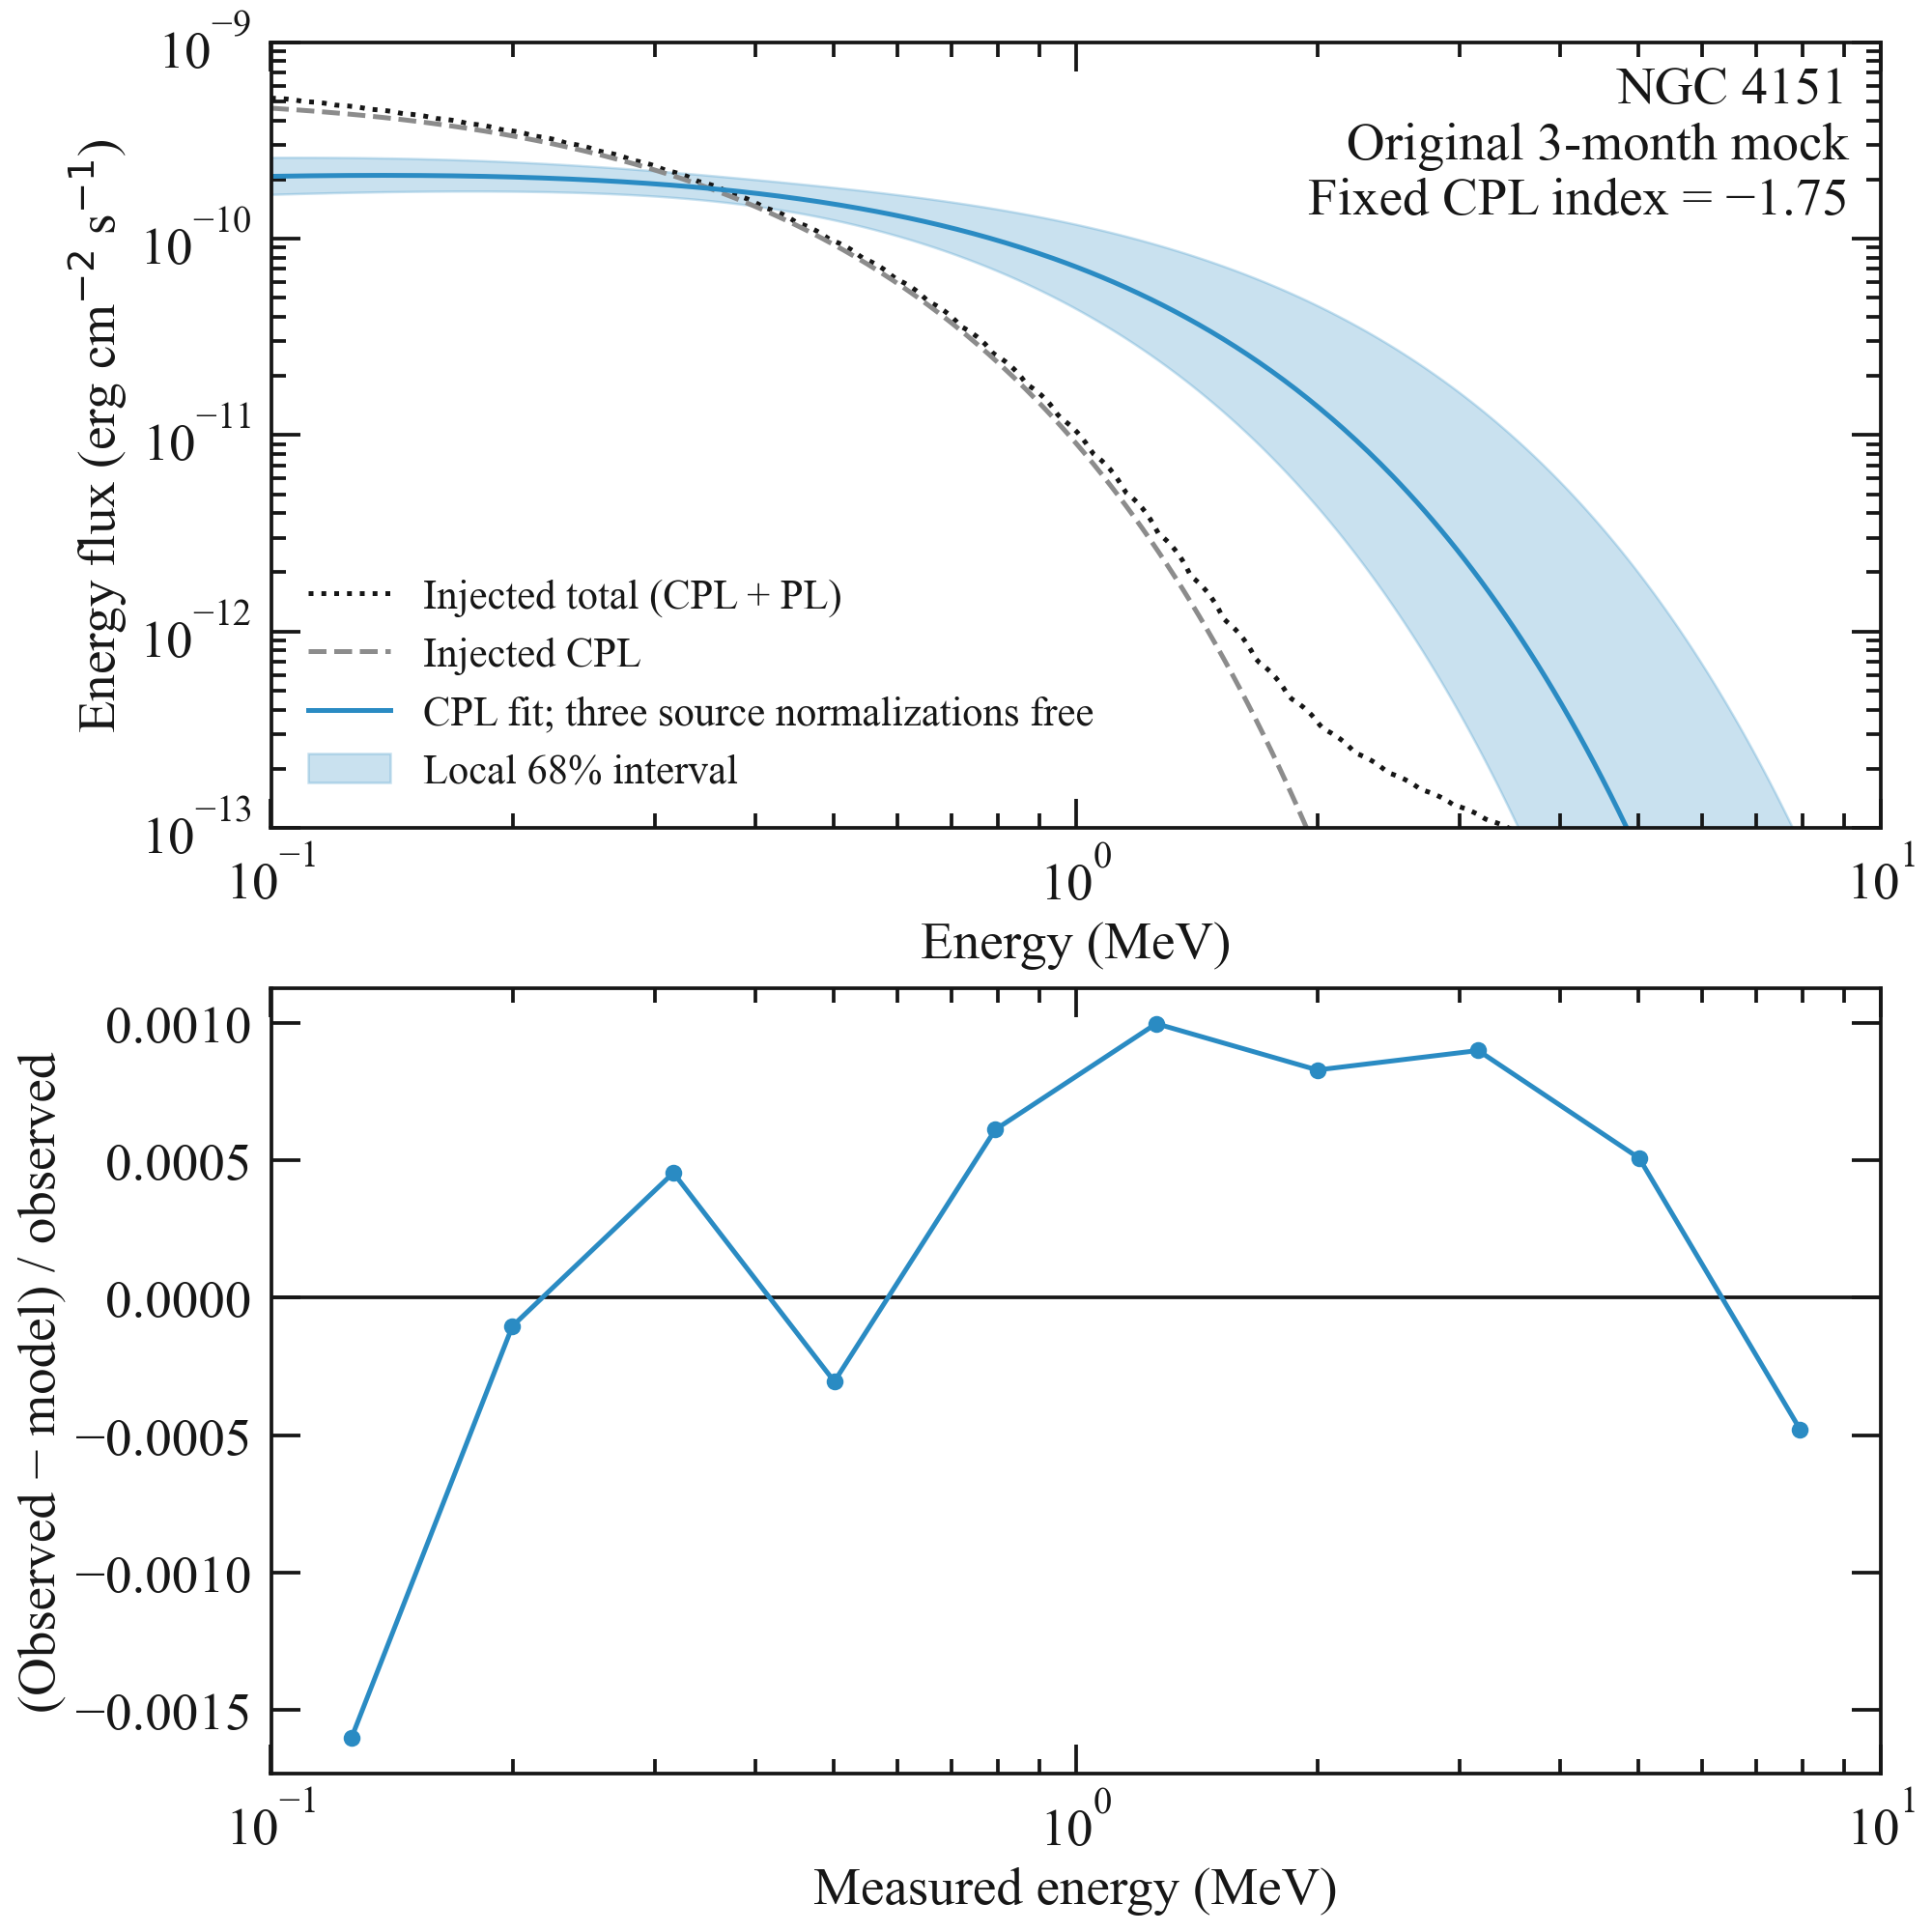

Observed counts: 26164189
Model counts: 26164216


In [18]:
# White paper figure: injected source, fixed-index catalog fit, and
# observed-versus-model measured-energy residuals.
original_ngc_spectrum_path=(source_library/'DC4/sources/Extragalactic/NGC_4151/NGC4151_ec200_TH_and_NTH_COSI.dat')
with original_ngc_spectrum_path.open() as f:
    original=np.asarray([[float(fields[1]),float(fields[2])] for line in f if (fields:=line.split()) and fields[0]=='DP'],dtype=float)
energy=np.geomspace(100.,10000.,400)
injected=np.interp(energy,original[:,0],original[:,1],left=np.nan,right=np.nan)
thermal=0.15*200.**(-1.75)*(energy/200.)**(-1.75)*np.exp(-energy/200.)
best_flux=np.asarray([fit_ngc.evaluate_at(e) for e in energy],dtype=float)
kev_to_erg=u.keV.to(u.erg)
band=None
if valid:
    pivot=float(fit_ngc.piv.value)
    def flux(values,e):
        return values[fit_ngc.K.path]*(e/pivot)**(-1.75)*np.exp(-e/values[fit_ngc.xc.path])
    try:
        band=local_log_flux_band(obj['joint'].results,energy,flux)
    except ValueError as exc:
        print('BAND UNAVAILABLE',exc,flush=True)

def dense(h):
    v=h.to_dense(copy=False).contents
    if hasattr(v,'compute'):v=v.compute()
    if hasattr(v,'value'):v=v.value
    return np.asarray(v,dtype=float).copy()
predicted=obj['folding'].expectation(copy=True)
predicted+=obj['background'].expectation(copy=True)
data_em=dense(data_hist.project('Em'))
model_em=dense(predicted.project('Em'))
edges=data_hist.axes['Em'].edges.to_value(u.keV)
centers=np.sqrt(edges[:-1]*edges[1:])/1000.
row['observed_counts']=float(data_em.sum())
row['model_counts']=float(model_em.sum())
plot_data = {
    'energy_keV': energy.tolist(), 'injected_photon_flux': injected.tolist(),
    'thermal_photon_flux': thermal.tolist(), 'best_photon_flux': best_flux.tolist(),
    'band_low': None if band is None else band[0].tolist(),
    'band_high': None if band is None else band[1].tolist(),
    'measured_energy_MeV': centers.tolist(),
    'observed_counts_by_energy': data_em.tolist(),
    'model_counts_by_energy': model_em.tolist(),
}
out_json.write_text(json.dumps({'data':str(mock_data_path),'catalog':str(parallel_catalog_path),
    'fixed_index':-1.75,'three_source_normalizations':['Crab','MAXI J1820','4C+21.35 flare'],
    'screening_starts':results,'best_fit':row,'plot_data':plot_data},indent=2)+'\n')

with paper_style('light',22):
    fig,(ax,rx)=plt.subplots(2,1,figsize=(11,11),constrained_layout=True)
    style_axis(ax,'light',22);style_axis(rx,'light',22)
    ax.plot(energy/1000.,kev_to_erg*energy**2*injected,color=ink('light'),ls=':',label='Injected total (CPL + PL)')
    ax.plot(energy/1000.,kev_to_erg*energy**2*thermal,color='0.55',ls='--',label='Injected CPL')
    ax.plot(energy/1000.,kev_to_erg*energy**2*best_flux,color=BLUE,label='CPL fit; three source normalizations free')
    if band is not None:
        ax.fill_between(energy/1000.,kev_to_erg*energy**2*band[0],kev_to_erg*energy**2*band[1],color=BLUE,alpha=.25,label='Local 68% interval')
    ax.set(xscale='log',yscale='log',xlim=(.1,10.),ylim=(1e-13,1e-9),xlabel='Energy (MeV)',ylabel=r'Energy flux (erg cm$^{-2}$ s$^{-1}$)')
    ax.text(.98,.97,'NGC 4151\nOriginal 3-month mock\nFixed CPL index = −1.75',transform=ax.transAxes,ha='right',va='top')
    ax.legend(frameon=False,loc='lower left',fontsize=17)
    rx.axhline(0.,color=ink('light'),lw=1.5)
    rx.plot(centers,(data_em-model_em)/np.maximum(data_em,1.),'o-',color=BLUE)
    rx.set(xscale='log',xlim=(.1,10.),xlabel='Measured energy (MeV)',ylabel='(Observed − model) / observed')
    for ext in ('pdf','png'):
        p=plot_dir/f'NGC4151_DC4_original_mock_three_nuisance_fixed_index_white.{ext}'
        fig.savefig(p,dpi=180,facecolor='white')
        print('SAVED PLOT',p,flush=True)
    plt.show()
    plt.close(fig)
# Keep the paper exports alongside the executed notebook.
import shutil
paper_dir = Path('/Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper')
paper_dir.mkdir(parents=True, exist_ok=True)
for artifact in (out_json, plot_dir / 'NGC4151_DC4_original_mock_three_nuisance_fixed_index_white.pdf',
                 plot_dir / 'NGC4151_DC4_original_mock_three_nuisance_fixed_index_white.png'):
    shutil.copy2(artifact, paper_dir / artifact.name)
    print('Paper export:', paper_dir / artifact.name)
